In [1]:

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip install -q openai tqdm

import os
import json
import re
import time
import pandas as pd
from tqdm import tqdm
from openai import OpenAI

CN_PATH = "/content/drive/MyDrive/conversation_cn.json"
EN_PATH = "/content/drive/MyDrive/conversation_cn_translated_en_deepseek_v4flash.json"

OUT_SAMPLE_PATH = "/content/drive/MyDrive/translation_quality_audit_50_samples.csv"
OUT_RESULT_PATH = "/content/drive/MyDrive/translation_quality_audit_50_results_gpt4omini.csv"

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]


client = OpenAI(
    api_key=OPENAI_API_KEY
)

MODEL_NAME = "gpt-4o-mini"

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise"]


def extract_json(raw):
    raw = raw.strip()

    raw = (
        raw.removeprefix("```json")
        .removeprefix("```")
        .removesuffix("```")
        .strip()
    )

    try:
        return json.loads(raw)

    except Exception:
        match = re.search(r"\{.*\}", raw, re.DOTALL)

        if match:
            return json.loads(match.group(0))

        raise


# =========================
# LOAD DATA
# =========================
with open(CN_PATH, "r", encoding="utf-8") as f:
    cn_data = json.load(f)

with open(EN_PATH, "r", encoding="utf-8") as f:
    en_data = json.load(f)

rows = []

for cn_conv, en_conv in zip(cn_data, en_data):

    conv_id = cn_conv.get("conv_id")

    for i, (cn_turn, en_turn) in enumerate(
        zip(cn_conv["conversation"], en_conv["conversation"])
    ):

        role = str(cn_turn.get("role", "")).lower()
        intent = cn_turn.get("intent")

        if role == "user" and intent in VALID_LABELS:

            rows.append({
                "conv_id": conv_id,
                "turn_index": i,
                "intent": intent,
                "chinese_text": cn_turn.get("content", ""),
                "english_translation": en_turn.get("content", "")
            })

sample_df = (
    pd.DataFrame(rows)
    .sample(n=50, random_state=42)
    .reset_index(drop=True)
)

sample_df.to_csv(OUT_SAMPLE_PATH, index=False)

print("Saved sample CSV:")
print(OUT_SAMPLE_PATH)

display(sample_df.head())


# =========================
# GPT-4o-mini JUDGE
# =========================
def judge_translation(row, max_retries=5):

    prompt = f"""
Evaluate this Chinese-to-English translation for a conversational intent classification dataset.

Intent label:
{row['intent']}

Chinese original:
{row['chinese_text']}

English translation:
{row['english_translation']}

Score each criterion from 1 to 5:
1 = poor
3 = acceptable
5 = excellent

Criteria:
- meaning_preserved
- intent_preserved
- detail_faithfulness

detail_faithfulness means:
Do not add/remove important details such as:
negation, product type, brand, quantity, preference, comparison, rejection, refinement, color, size, price.

Return ONLY valid JSON in this exact format:

{{
  "meaning_preserved": 5,
  "intent_preserved": 5,
  "detail_faithfulness": 5,
  "brief_reason": "short explanation"
}}
""".strip()

    for attempt in range(max_retries):

        try:
            response = client.chat.completions.create(
                model=MODEL_NAME,
                messages=[
                    {
                        "role": "system",
                        "content": (
                            "You are a strict bilingual evaluator for conversational AI datasets. "
                            "Return only valid JSON."
                        )
                    },
                    {
                        "role": "user",
                        "content": prompt
                    }
                ],
                temperature=0,
                max_tokens=300,
            )

            raw = response.choices[0].message.content

            result = extract_json(raw)

            return {
                "meaning_preserved": int(result["meaning_preserved"]),
                "intent_preserved": int(result["intent_preserved"]),
                "detail_faithfulness": int(result["detail_faithfulness"]),
                "brief_reason": str(result.get("brief_reason", ""))
            }

        except Exception as e:

            wait = 2 ** attempt

            print(f"Judge error, retrying in {wait}s: {e}")

            time.sleep(wait)

    return {
        "meaning_preserved": None,
        "intent_preserved": None,
        "detail_faithfulness": None,
        "brief_reason": "FAILED_TO_JUDGE"
    }


# =========================
# RUN AUDIT
# =========================
results = []

for _, row in tqdm(
    sample_df.iterrows(),
    total=len(sample_df),
    desc="Evaluating translations"
):

    score = judge_translation(row)

    results.append(score)

audit_df = pd.concat(
    [sample_df.reset_index(drop=True), pd.DataFrame(results)],
    axis=1
)

audit_df.to_csv(OUT_RESULT_PATH, index=False)

print("\nSaved audit results:")
print(OUT_RESULT_PATH)

display(audit_df.head())


# =========================
# SUMMARY
# =========================
print("\nAverage scores:")

display(
    audit_df[[
        "meaning_preserved",
        "intent_preserved",
        "detail_faithfulness"
    ]].mean()
)

print("\nDetailed score distribution:")

display(
    audit_df[[
        "meaning_preserved",
        "intent_preserved",
        "detail_faithfulness"
    ]].describe()
)

Saved sample CSV:
/content/drive/MyDrive/translation_quality_audit_50_samples.csv


,conv_id,turn_index,intent,chinese_text,english_translation
0,86909,0,Reveal,请问有洗碗巾吗？,Do you have dishcloths?
1,2642,0,Chitchat,你好呀,Hello there
2,74141,6,Interpret,这一款还可以，谢谢推荐,"This one is okay, thanks for the recommendation."
3,74221,2,Interpret,不喜欢这款，换一个呢？,"I don't like this one, can I see another?"
4,48864,7,Interpret,白色或黑色的,White or black.


Evaluating translations: 100%|██████████| 50/50 [01:44<00:00,  2.09s/it]


Saved audit results:
/content/drive/MyDrive/translation_quality_audit_50_results_gpt4omini.csv


,conv_id,turn_index,intent,chinese_text,english_translation,meaning_preserved,intent_preserved,detail_faithfulness,brief_reason
0,86909,0,Reveal,请问有洗碗巾吗？,Do you have dishcloths?,5,5,5,The translation accurately conveys the origina...
1,2642,0,Chitchat,你好呀,Hello there,5,5,5,The translation accurately conveys the greetin...
2,74141,6,Interpret,这一款还可以，谢谢推荐,"This one is okay, thanks for the recommendation.",5,5,5,The translation accurately conveys the origina...
3,74221,2,Interpret,不喜欢这款，换一个呢？,"I don't like this one, can I see another?",5,5,5,The translation accurately conveys the origina...
4,48864,7,Interpret,白色或黑色的,White or black.,5,5,5,The translation accurately conveys the color o...



Average scores:


,0
meaning_preserved,4.90
intent_preserved,4.92
detail_faithfulness,4.86



Detailed score distribution:


,meaning_preserved,intent_preserved,detail_faithfulness
count,50.000000,50.000000,50.000000
mean,4.900000,4.920000,4.860000
std,0.580288,0.565685,0.639196
min,1.000000,1.000000,1.000000
25%,5.000000,5.000000,5.000000
50%,5.000000,5.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


,metric,mean_score
0,Meaning Preserved,4.90
1,Intent Preserved,4.92
2,Detail Faithfulness,4.86


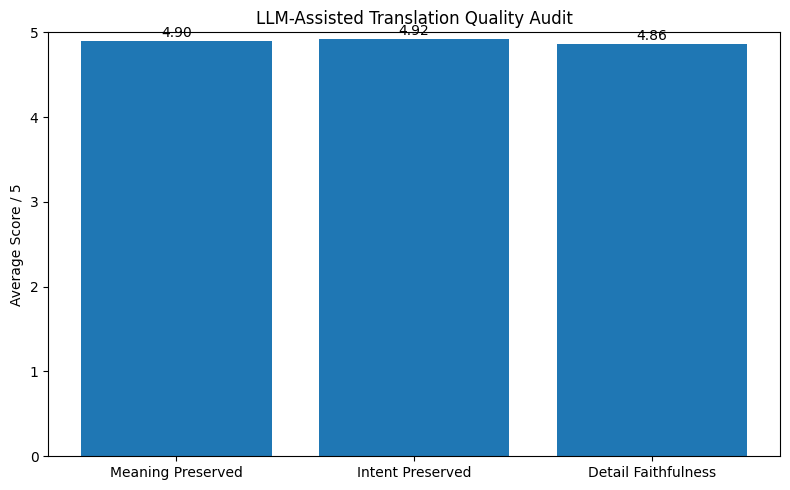

Saved plot to: /content/drive/MyDrive/translation_quality_audit_scores.png


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

AUDIT_PATH = "/content/drive/MyDrive/translation_quality_audit_50_results_gpt4omini.csv"
OUT_PATH = "/content/drive/MyDrive/translation_quality_audit_scores.png"

audit_df = pd.read_csv(AUDIT_PATH)

score_means = audit_df[
    ["meaning_preserved", "intent_preserved", "detail_faithfulness"]
].mean().reset_index()

score_means.columns = ["metric", "mean_score"]

score_means["metric"] = score_means["metric"].replace({
    "meaning_preserved": "Meaning Preserved",
    "intent_preserved": "Intent Preserved",
    "detail_faithfulness": "Detail Faithfulness"
})

display(score_means)

plt.figure(figsize=(8, 5))

plt.bar(
    score_means["metric"],
    score_means["mean_score"]
)

plt.ylim(0, 5)
plt.ylabel("Average Score / 5")
plt.title("LLM-Assisted Translation Quality Audit")

for i, row in score_means.iterrows():
    plt.text(
        i,
        row["mean_score"] + 0.05,
        f"{row['mean_score']:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print("Saved plot to:", OUT_PATH)

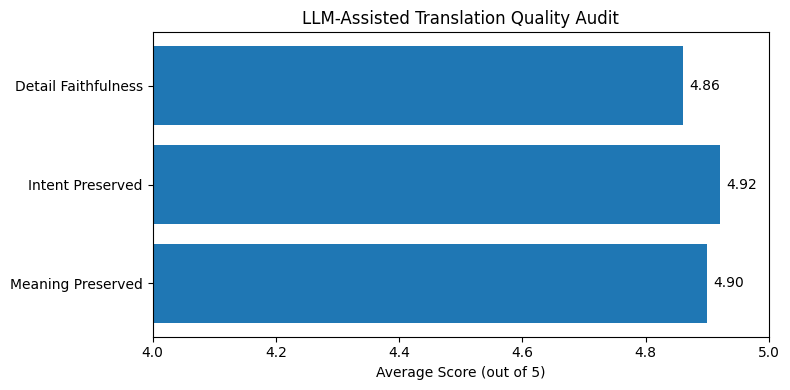

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

AUDIT_PATH = "/content/drive/MyDrive/translation_quality_audit_50_results_gpt4omini.csv"

audit_df = pd.read_csv(AUDIT_PATH)

score_means = audit_df[
    ["meaning_preserved", "intent_preserved", "detail_faithfulness"]
].mean()

score_means.index = [
    "Meaning Preserved",
    "Intent Preserved",
    "Detail Faithfulness"
]

plt.figure(figsize=(8, 4))

bars = plt.barh(
    score_means.index,
    score_means.values
)

# Zoom near upper range
plt.xlim(4.0, 5.0)

plt.xlabel("Average Score (out of 5)")
plt.title("LLM-Assisted Translation Quality Audit")

for bar, val in zip(bars, score_means.values):
    plt.text(
        val + 0.01,
        bar.get_y() + bar.get_height()/2,
        f"{val:.2f}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/translation_quality_audit_scores_improved.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()